In [1]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator 
import matplotlib.pyplot as plt
import os
import cv2
from tensorflow.keras.models import load_model


In [2]:
# Define paths for the dataset directories
base_dir = './data'
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')
test_dir = os.path.join(base_dir, 'test')


In [3]:
# Data augmentation for training
train_datagen = ImageDataGenerator(
    rescale=1.0/255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Only rescale for validation and test
val_datagen = ImageDataGenerator(rescale=1.0/255)
test_datagen = ImageDataGenerator(rescale=1.0/255)

# Load images from the directories
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(150, 150),
    batch_size=32,
    class_mode='binary'
)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=(150, 150),
    batch_size=32,
    class_mode='binary'
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(150, 150),
    batch_size=32,
    class_mode='binary'
)


Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


In [4]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(512, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation='sigmoid')
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [5]:
from tensorflow.keras.callbacks import Callback
import matplotlib.pyplot as plt
import numpy as np

class VisualizeBatch(Callback):
    def on_epoch_end(self, epoch, logs=None):
        # Get a batch of images and labels from the training set
        images, labels = next(train_generator)
        
        # Make predictions on the batch
        predictions = self.model.predict(images)
        
        # Display the first 5 images and their predictions
        plt.figure(figsize=(15, 5))
        for i in range(5):
            plt.subplot(1, 5, i+1)
            plt.imshow(images[i])
            true_label = "Pneumonia" if labels[i] == 1 else "Normal"
            predicted_label = "Pneumonia" if predictions[i] > 0.5 else "Normal"
            plt.title(f"True: {true_label}\nPred: {predicted_label}")
            plt.axis('off')
        plt.show()

c:\Users\Famim\.project\.venv\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 473ms/step - accuracy: 0.7382 - loss: 0.7307

c:\Users\Famim\.project\.venv\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step


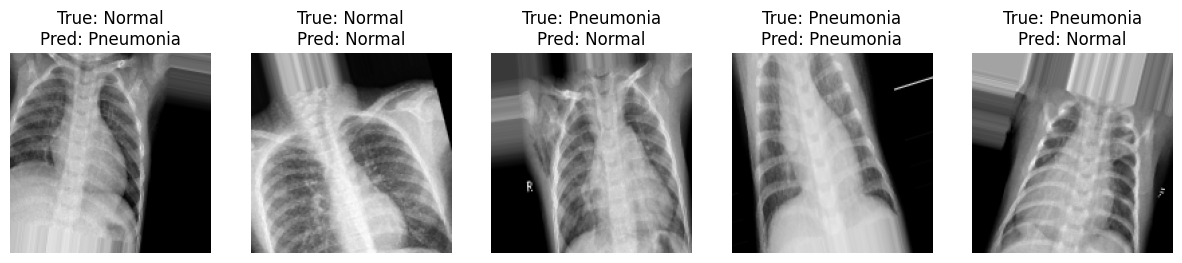

163/163 ━━━━━━━━━━━━━━━━━━━━ 80s 479ms/step - accuracy: 0.7385 - loss: 0.7293 - val_accuracy: 0.8125 - val_loss: 0.5528
Epoch 2/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step/step - accuracy: 0.8453 - loss: 0.330


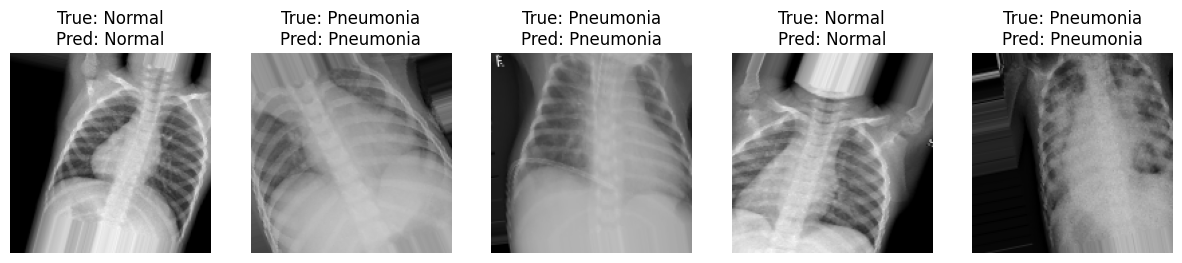

163/163 ━━━━━━━━━━━━━━━━━━━━ 75s 462ms/step - accuracy: 0.8453 - loss: 0.3299 - val_accuracy: 0.6875 - val_loss: 0.7509
Epoch 3/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step/step - accuracy: 0.8725 - loss: 0.297


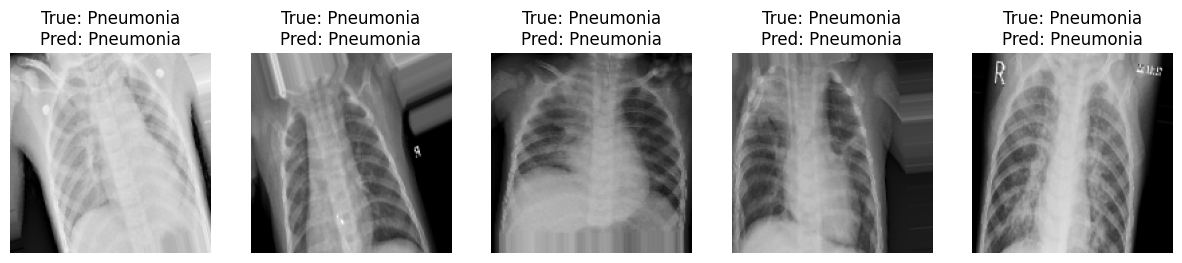

163/163 ━━━━━━━━━━━━━━━━━━━━ 72s 442ms/step - accuracy: 0.8725 - loss: 0.2978 - val_accuracy: 0.8125 - val_loss: 0.4746
Epoch 4/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step/step - accuracy: 0.8966 - loss: 0.239


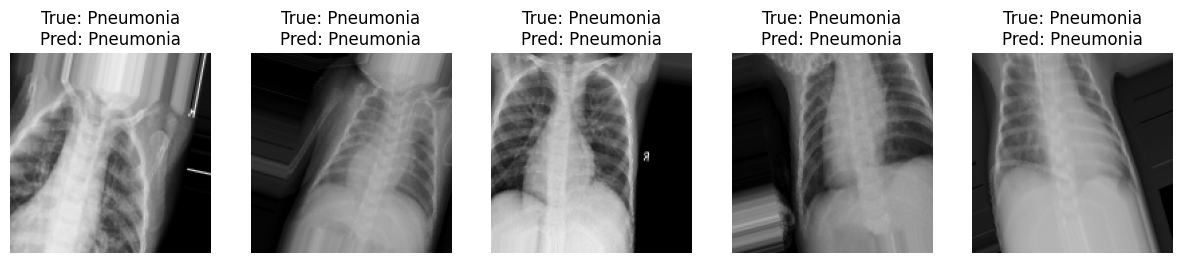

163/163 ━━━━━━━━━━━━━━━━━━━━ 72s 438ms/step - accuracy: 0.8966 - loss: 0.2396 - val_accuracy: 0.6875 - val_loss: 0.7059
Epoch 5/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step/step - accuracy: 0.9089 - loss: 0.209


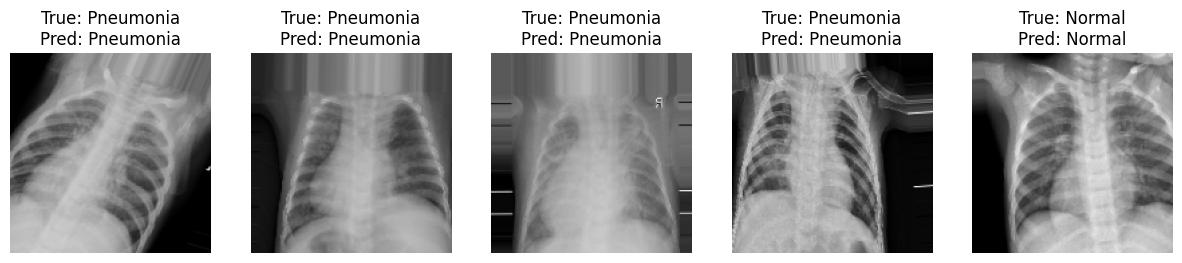

163/163 ━━━━━━━━━━━━━━━━━━━━ 73s 445ms/step - accuracy: 0.9089 - loss: 0.2099 - val_accuracy: 0.8125 - val_loss: 0.3390
Epoch 6/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step/step - accuracy: 0.9082 - loss: 0.222


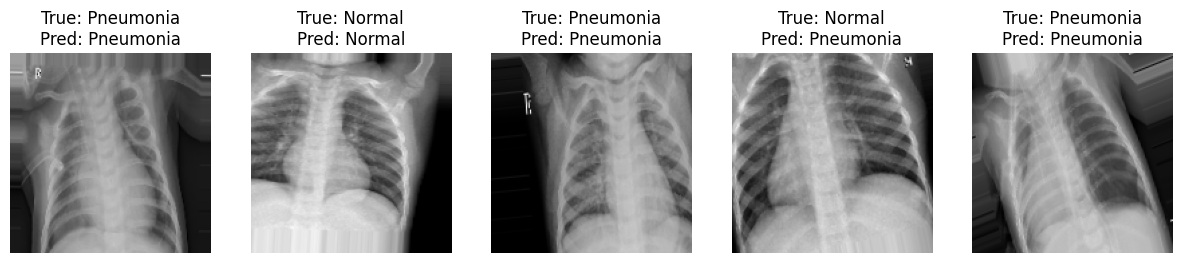

163/163 ━━━━━━━━━━━━━━━━━━━━ 72s 438ms/step - accuracy: 0.9082 - loss: 0.2222 - val_accuracy: 0.8750 - val_loss: 0.3257
Epoch 7/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step/step - accuracy: 0.9018 - loss: 0.222


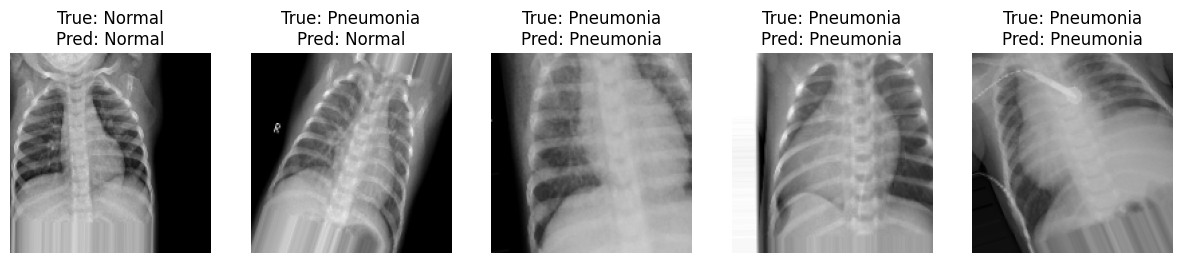

163/163 ━━━━━━━━━━━━━━━━━━━━ 72s 443ms/step - accuracy: 0.9018 - loss: 0.2227 - val_accuracy: 0.8750 - val_loss: 0.2764
Epoch 8/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step/step - accuracy: 0.9229 - loss: 0.183


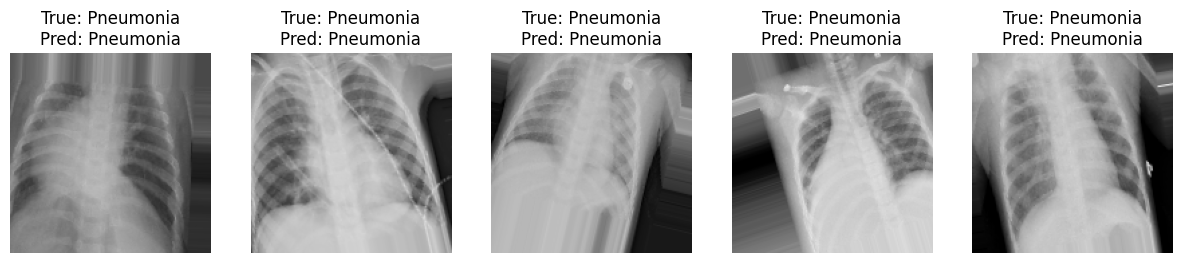

163/163 ━━━━━━━━━━━━━━━━━━━━ 72s 443ms/step - accuracy: 0.9229 - loss: 0.1837 - val_accuracy: 0.8750 - val_loss: 0.3079
Epoch 9/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step/step - accuracy: 0.9210 - loss: 0.190


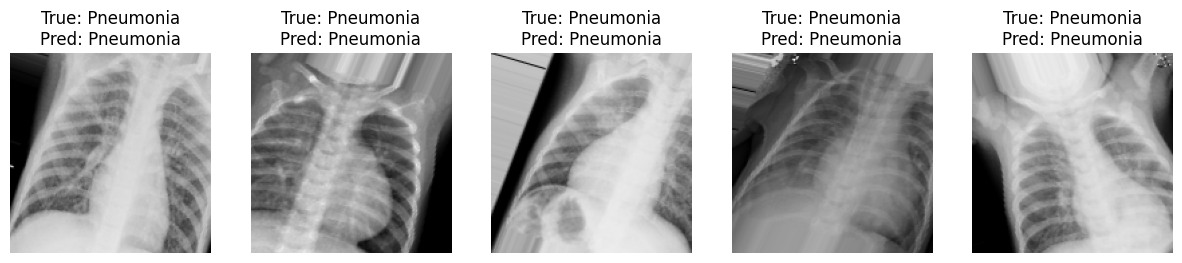

163/163 ━━━━━━━━━━━━━━━━━━━━ 74s 455ms/step - accuracy: 0.9210 - loss: 0.1901 - val_accuracy: 0.8125 - val_loss: 0.2556
Epoch 10/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step/step - accuracy: 0.9317 - loss: 0.178


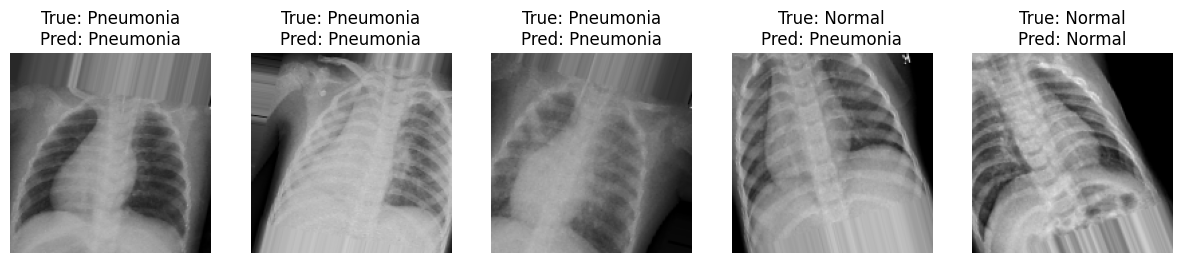

163/163 ━━━━━━━━━━━━━━━━━━━━ 71s 436ms/step - accuracy: 0.9316 - loss: 0.1781 - val_accuracy: 0.8750 - val_loss: 0.2898


In [6]:
history = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // train_generator.batch_size,
    epochs=10,  # You can adjust the number of epochs
    validation_data=val_generator,
    validation_steps=val_generator.samples // val_generator.batch_size,
    callbacks=[VisualizeBatch()]
)

In [7]:
model.save('pneumonia_model.h5')

In [8]:
test_loss, test_acc = model.evaluate(test_generator)
print(f"Test accuracy: {test_acc:.2f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 197ms/step - accuracy: 0.8798 - loss: 0.3212
Test accuracy: 0.88


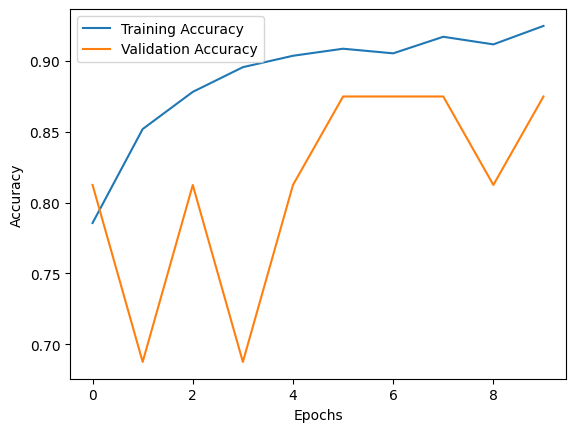

In [9]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history.get('val_accuracy', history.history.get('val_acc', [])), label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [10]:
from tensorflow.keras.preprocessing import image

# Load the model
model = load_model("pneumonia_model.h5")

# Load and preprocess the image
img_path = "C:/Users/Famim/.project/data/test/PNEUMONIA/person1_virus_6.jpeg"  # Make sure the correct extension is used (.jpg, .jpeg, .png, etc.)
img = image.load_img(img_path, target_size=(150, 150))  # Change (224, 224) to your model's input size
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = img_array / 255.0  # normalize

# Predict
prediction = model.predict(img_array)[0][0]
print("Prediction:", prediction)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
Prediction: 0.9995101
